<a href="https://colab.research.google.com/github/reginamtxg/M-todos-num-ricos-I/blob/main/MetNewton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Metodo de Newton**  
*Garcia Martinez Regina*  
algoritmo 2.3 | Burden

Para encontarar una solucion a
$f(x)=cos x - x = 0$ dada una aproximación inicial $p_0$:  
Entrada: Aproximación inicial $p_0$; tolerancia $TOL$; número máximo de iteraciones $N_0$

In [43]:
# librerias para calculo y visualización
import numpy as np
import matplotlib.pyplot as plt

# Configuraciun para las graficas en matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

In [44]:
def metodo_newton(f, df, p0, TOL, N0):
    """
    Implementacion del metodo de Newton
    Parametros:
    - f: Funcion de la cual se desea encontrar la raiz
    - df: Derivada analitica de la funcion f
    - p0: Aproximacion inicial
    - TOL: Tolerancia para el criterio de paro
    - N0: Numero maximo de iteraciones permitidas

    Retorna:
    - p: Raiz aproximada encontrada
    - historial: Lista con el registro de cada iteracion
    """
    historial = []
    i = 1

    print(f"{'n':<15}  {'p_n':<18}  {'f(p_n)':<18}  {'ε|p_n - p_{n-1}|'}")
    print("-" * 75)

    while i <= N0:
        f_p0 = f(p0)
        df_p0 = df(p0)

        # Buscamos evitar division por cero en la derivada
        if df_p0 == 0:
            raise ValueError(f"Derivada nula en p = {p0}, el metodo no puede continuar")

        # Paso 3: Formula de Newton
        p = p0 - (f_p0 / df_p0)

        # Calculo del error absoluto respecto a la iteracion
        error = abs(p - p0)
        historial.append((i, p, f_p0, error))

        print(f"{i:<15}  {p:<18.8f}  {f_p0:<18.8e}  {error:<18.8e}")

        # Paso 4: Condicion de TOL
        if error < TOL:
            print("-" * 75)
            print(f"\nEl proceso fue exitoso y convergio en la raiz p = {p:.8f} en {i} iteraciones")
            return p, historial

        # Pasos 5 y 6: Actualizacion de contadores y p0
        i += 1
        p0 = p

    print(f"\nEl metodo no convergio tras alcanzar el maximo de {N0} iteraciones")
    return None, historial

 Aplicación: Ejemplo 1 (Burden, pag 51)

Aplicamos el Algoritmo 2.3 al Ejemplo 1 del libro:

$$f(x) = \cos(x) - x$$

necesitamos su derivada para desarrollar la formula, la cual es:

$$f'(x) = -\sin(x) - 1$$  

 con los  datos:
* $p_0 = \frac{\pi}{4} \approx 0.78539816$
* $TOL = 10^{-7}$
* $N_0 = 20$

In [45]:
# Definicion de la funcion y su derivada
f = lambda x: np.cos(x) - x
df = lambda x: -np.sin(x) - 1

# Parametros iniciales del problema
p0 = np.pi / 4
TOL = 1e-7
N0 = 20

# Ejecucion del algoritmo
raiz_aproximada, historial = metodo_newton(f, df, p0, TOL, N0)

n                p_n                 f(p_n)              ε|p_n - p_{n-1}|
---------------------------------------------------------------------------
1                0.73953613          -7.82913822e-02     4.58620299e-02    
2                0.73908518          -7.54874683e-04     4.50955409e-04    
3                0.73908513          -7.51298664e-08     4.48908490e-08    
---------------------------------------------------------------------------

El proceso fue exitoso y convergio en la raiz p = 0.73908513 en 3 iteraciones


Grafica de Convergencia

muestra el comportamiento de la función $f(x) = \cos(x) - x$ y la ubicación exacta de la raiz encontrada

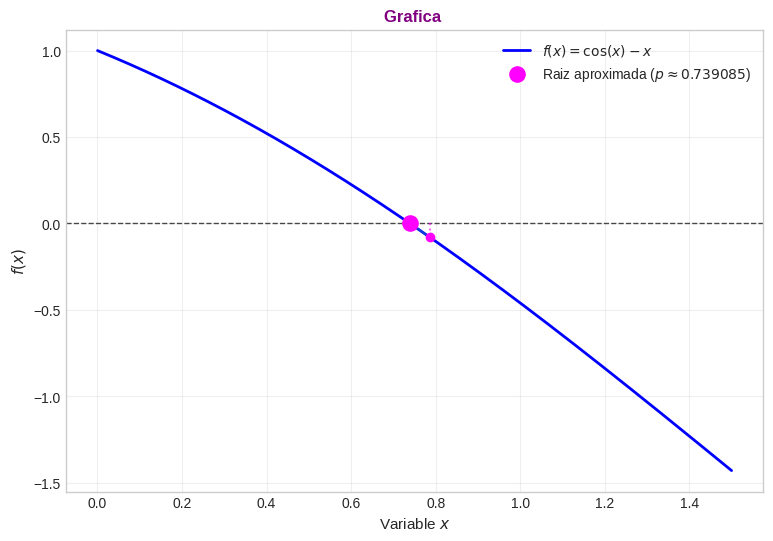

In [46]:
# Rango de evaluación para la gráfica
x_vals = np.linspace(0, 1.5, 400)
y_vals = f(x_vals)

plt.figure(figsize=(9, 6))
plt.plot(x_vals, y_vals, label='$f(x) = \\cos(x) - x$', color='blue', linewidth=2)
plt.axhline(0, color='black', linewidth=1, linestyle='--', alpha=0.7)

# Trazado de las aproximaciones sucesivas del método
p_actual = p0
for item in historial:
    i, p_next, f_p, error = item
    # Línea vertical indicando la evaluación y salto a la raíz
    plt.plot([p_actual, p_actual], [0, f(p_actual)], color='magenta', linestyle=':', alpha=0.6)
    plt.plot([p_actual, p_next], [f(p_actual), 0], linestyle='-', alpha=0.5)
    plt.scatter([p_actual], [f(p_actual)], color='magenta', zorder=5)
    p_actual = p_next

# Marcar la raíz final obtenida en la gráfica
plt.scatter([raiz_aproximada], [0], color='magenta', s=120, zorder=6, label=f'Raiz aproximada ($p \\approx {raiz_aproximada:.6f}$)')

plt.title('Grafica ', fontsize=12, fontweight='bold', color='purple')
plt.xlabel('Variable $x$', fontsize=11)
plt.ylabel('$f(x)$', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()